In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox
from halcyon.Models.MechanisticModel import PyTorchODE
from halcyon.Models.HybridModel import HybridModel
from halcyon.Trainer import Trainer
from halcyon.FittedTrainerList import FittedTrainerList
from halcyon.Losses import MSELossPlusMachineLearningL2
from copy import deepcopy
from halcyon.Simulators.GNWSimRunner import SimulationResult

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Simulating data

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [10]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [2]
sparsity_list = [0.02]
out_path = Path("../data/hybrid_model_first_tests") 

sim_outputs: list[SimulationResult] = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = out_path / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_output = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
                keep_self_interactions=False
            )
            sim_outputs.append(sim_output) 
sim_outputs

2025-12-01 15:14:46,155 - INFO - Generating network
2025-12-01 15:14:46,882 - INFO - Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_3*Node_5~Node_1) + ~(Node_2*Node_7)
my_network: Node_1: ~(Node_6) + (Node_3) + (Node_8) + (Node_4)
my_network: Node_2: ~(Node_5*Node_3~Node_0) + ~(Node_7)
my_network: Node_3: (Node_4*Node_6) + (Node_1*Node_2)
my_network: Node_4: (Node_3) + ~(Node_6) + (Node_1)
my_network: Node_5: (Node_0) + ~(Node_2)
my_network: Node_6: (Node_4*Node_3~Node_1)
my_network: Node_7: (Node_2~Node_0) + ~(Node_5)
my_network: Node_8: ~(Node_1)
my_network: Node_9: (Node_3)
Writing file /lustre/BIF/nobackup/noord087/phd/HALCYON/notebooks/../data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/my_network.xml

Thomas Schaffter (thomas.schaff.

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f8e14603400>)]

1


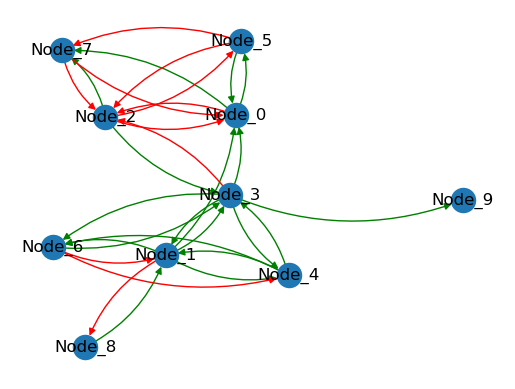

In [3]:
sim_output = sim_outputs[0]

from networkx import number_weakly_connected_components
print(number_weakly_connected_components(sim_output.network._graph))

sim_output.network.plot()
plt.show()

# Trainers (with different models) creation

In [4]:
train_jobs : list[Trainer] = []

## Mech model

In [5]:
# Generate MM from this
mm = PyTorchODE.from_sbml(sim_output.data_path / 'my_network.xml', condition_names=(), from_gnw=True, device='cpu')
# Select only genes from specific module
mm.select_genes([f'Node_{i}' for i in [0, 2 , 5, 7]])
# Fit MM on this data (skip for now?)
print(mm.modelled_gene_labels)
# Creating MM trainer even though it cannot be trained
mm_trainer = Trainer(
    mm,
    sim_output,
    batch_size=32,
    nr_training_steps=0,
    # optimizer_fn=lambda x: None
)

train_jobs.append(mm_trainer)
# mm_trainer.save(mm_trainer.save_path)

2025-12-01 15:14:56,535 - INFO - Loading SBML model from: /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/my_network.xml


['Node_0', 'Node_2', 'Node_5', 'Node_7']


## ML and Hybrid model

In [6]:
expr_data = sim_output.get_no_noise_ko_timeseries_expressiondata()

# for hidden_size in [2, 5, 10]:
#     for do_only_pos in [True, False]:

for hidden_size in [10]:
    for do_only_pos in [True]:        
        ml_model = PhoenixAddAndProdLayers(
                    modelled_gene_labels=expr_data.genes,
                    hidden_size=hidden_size,
                    condition_names=expr_data.all_environments,
                    synthesis_only_positive=do_only_pos,
                    device='cuda:1'
            )

        # trainer = Trainer(
        #     ml_model,
        #     sim_output,
        #     batch_size=32,
        #     nr_training_steps=1000,
        # )

        # train_jobs.append(trainer)
        # Create hybrid model with MM and cellbox with add and prod
        hybrid_model = HybridModel(deepcopy(mm), deepcopy(ml_model), device='cpu')

        for model in [ml_model, hybrid_model]:
            # my_loss = MSELossPlusMachineLearningL2(lambda_param=0.5)
            trainer = Trainer(
                model,
                sim_output,
                batch_size=32,
                nr_training_steps=200,
                optimizer_kwargs = {'lr': 0.1}
            )
            train_jobs.append(trainer)

In [7]:
for job in train_jobs:
    print(job)
    print()

Training PyTorchODE on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f8e14603400>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PyTorchODE.pt

Training PhoenixAddAndProdLayers on SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), network_name='my_network', nr_genes=10, nr_modules=2, sparsity=0.02, keep_self_interactions=False, network=<halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f8e14603400>). Saving to /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PhoenixAddAn

# Do training

In [ ]:
train_jobs[1].run_for_parallelisation_and_save()

In [8]:
mp.set_start_method("spawn", force=True)
with mp.Pool(processes=4) as pool:
    pool.map(run_training_job, train_jobs)

/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/sympy/core/sympify.py:449: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  return sympify(float(a))
2025-12-01 15:15:17,796 [SpawnPoolWorker-3] Epoch 0, loss 0.17073459923267365
2025-12-01 15:15:18,151 [SpawnPoolWorker-3] Epoch 1, loss 0.08723019808530807
2025-12-01 15:15:18,518 [SpawnPoolWorker-3] Epoch 2, loss 0.07639534771442413
2025-12-01 15:15:18,915 [SpawnPoolWorker-3] Epoch 3, loss 0.06907963752746582
2025-12-01 15:15:19,313 [SpawnPoolWorker-3] Epoch 4, loss 0.06463756412267685
2025-12-01 15:15:19,681 [SpawnPoolWorker-3] Epoch 5, loss 0.06109746918082237
2025-12-01 15:15:19,856 [SpawnPoolWorker-2] Epoch 0, loss 0.10414040833711624
2025-12-01 15:15:20,078 [SpawnPoolWorker-3] Epoch 6, loss 0.05859347805380821
2

MaybeEncodingError: Error sending result: '[{'final_loss': 0.0051993634551763535, 'nr_training_steps': 200, 'model_path': '/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PhoenixAddAndProdLayers_hidden_size_10_synthesis_only_positive_True_lr_0.1.pt', 'model_cls': 'PhoenixAddAndProdLayers', 'data_path': PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02'), 'network_name': 'my_network', 'nr_genes': 10, 'nr_modules': 2, 'sparsity': 0.02, 'keep_self_interactions': False, 'network': <halcyon.RegulatoryNetwork.RegulatoryNetwork object at 0x7f239ffb6d70>, 'device': device(type='cuda', index=1), 'hidden_size': 10, 'synthesis_only_positive': tensor(True, device='cuda:1'), 'lr': 0.1}]'. Reason: 'RuntimeError('Attempted to send CUDA tensor received from another process; this is not currently supported. Consider cloning before sending.')'

# Plot results

In [ ]:
train_jobs

In [21]:
# Currently loading hybrid / mechanistic model broken so will have to check this later. 
# The above implementation work (but doesnt load from saved files)
result_list = FittedTrainerList.load_saved_jobs(train_jobs)

2025-12-01 15:39:58,469 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PyTorchODE.pt
2025-12-01 15:40:11,020 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_PhoenixAddAndProdLayers_hidden_size_10_synthesis_only_positive_True_lr_0.1.pt
2025-12-01 15:40:14,056 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/hybrid_model_first_tests/genes_10_modules_2_sparsity_0.02/trained_trainer_HybridModel_hidden_size_10_synthesis_only_positive_True_lr_0.1.pt


## Single KO

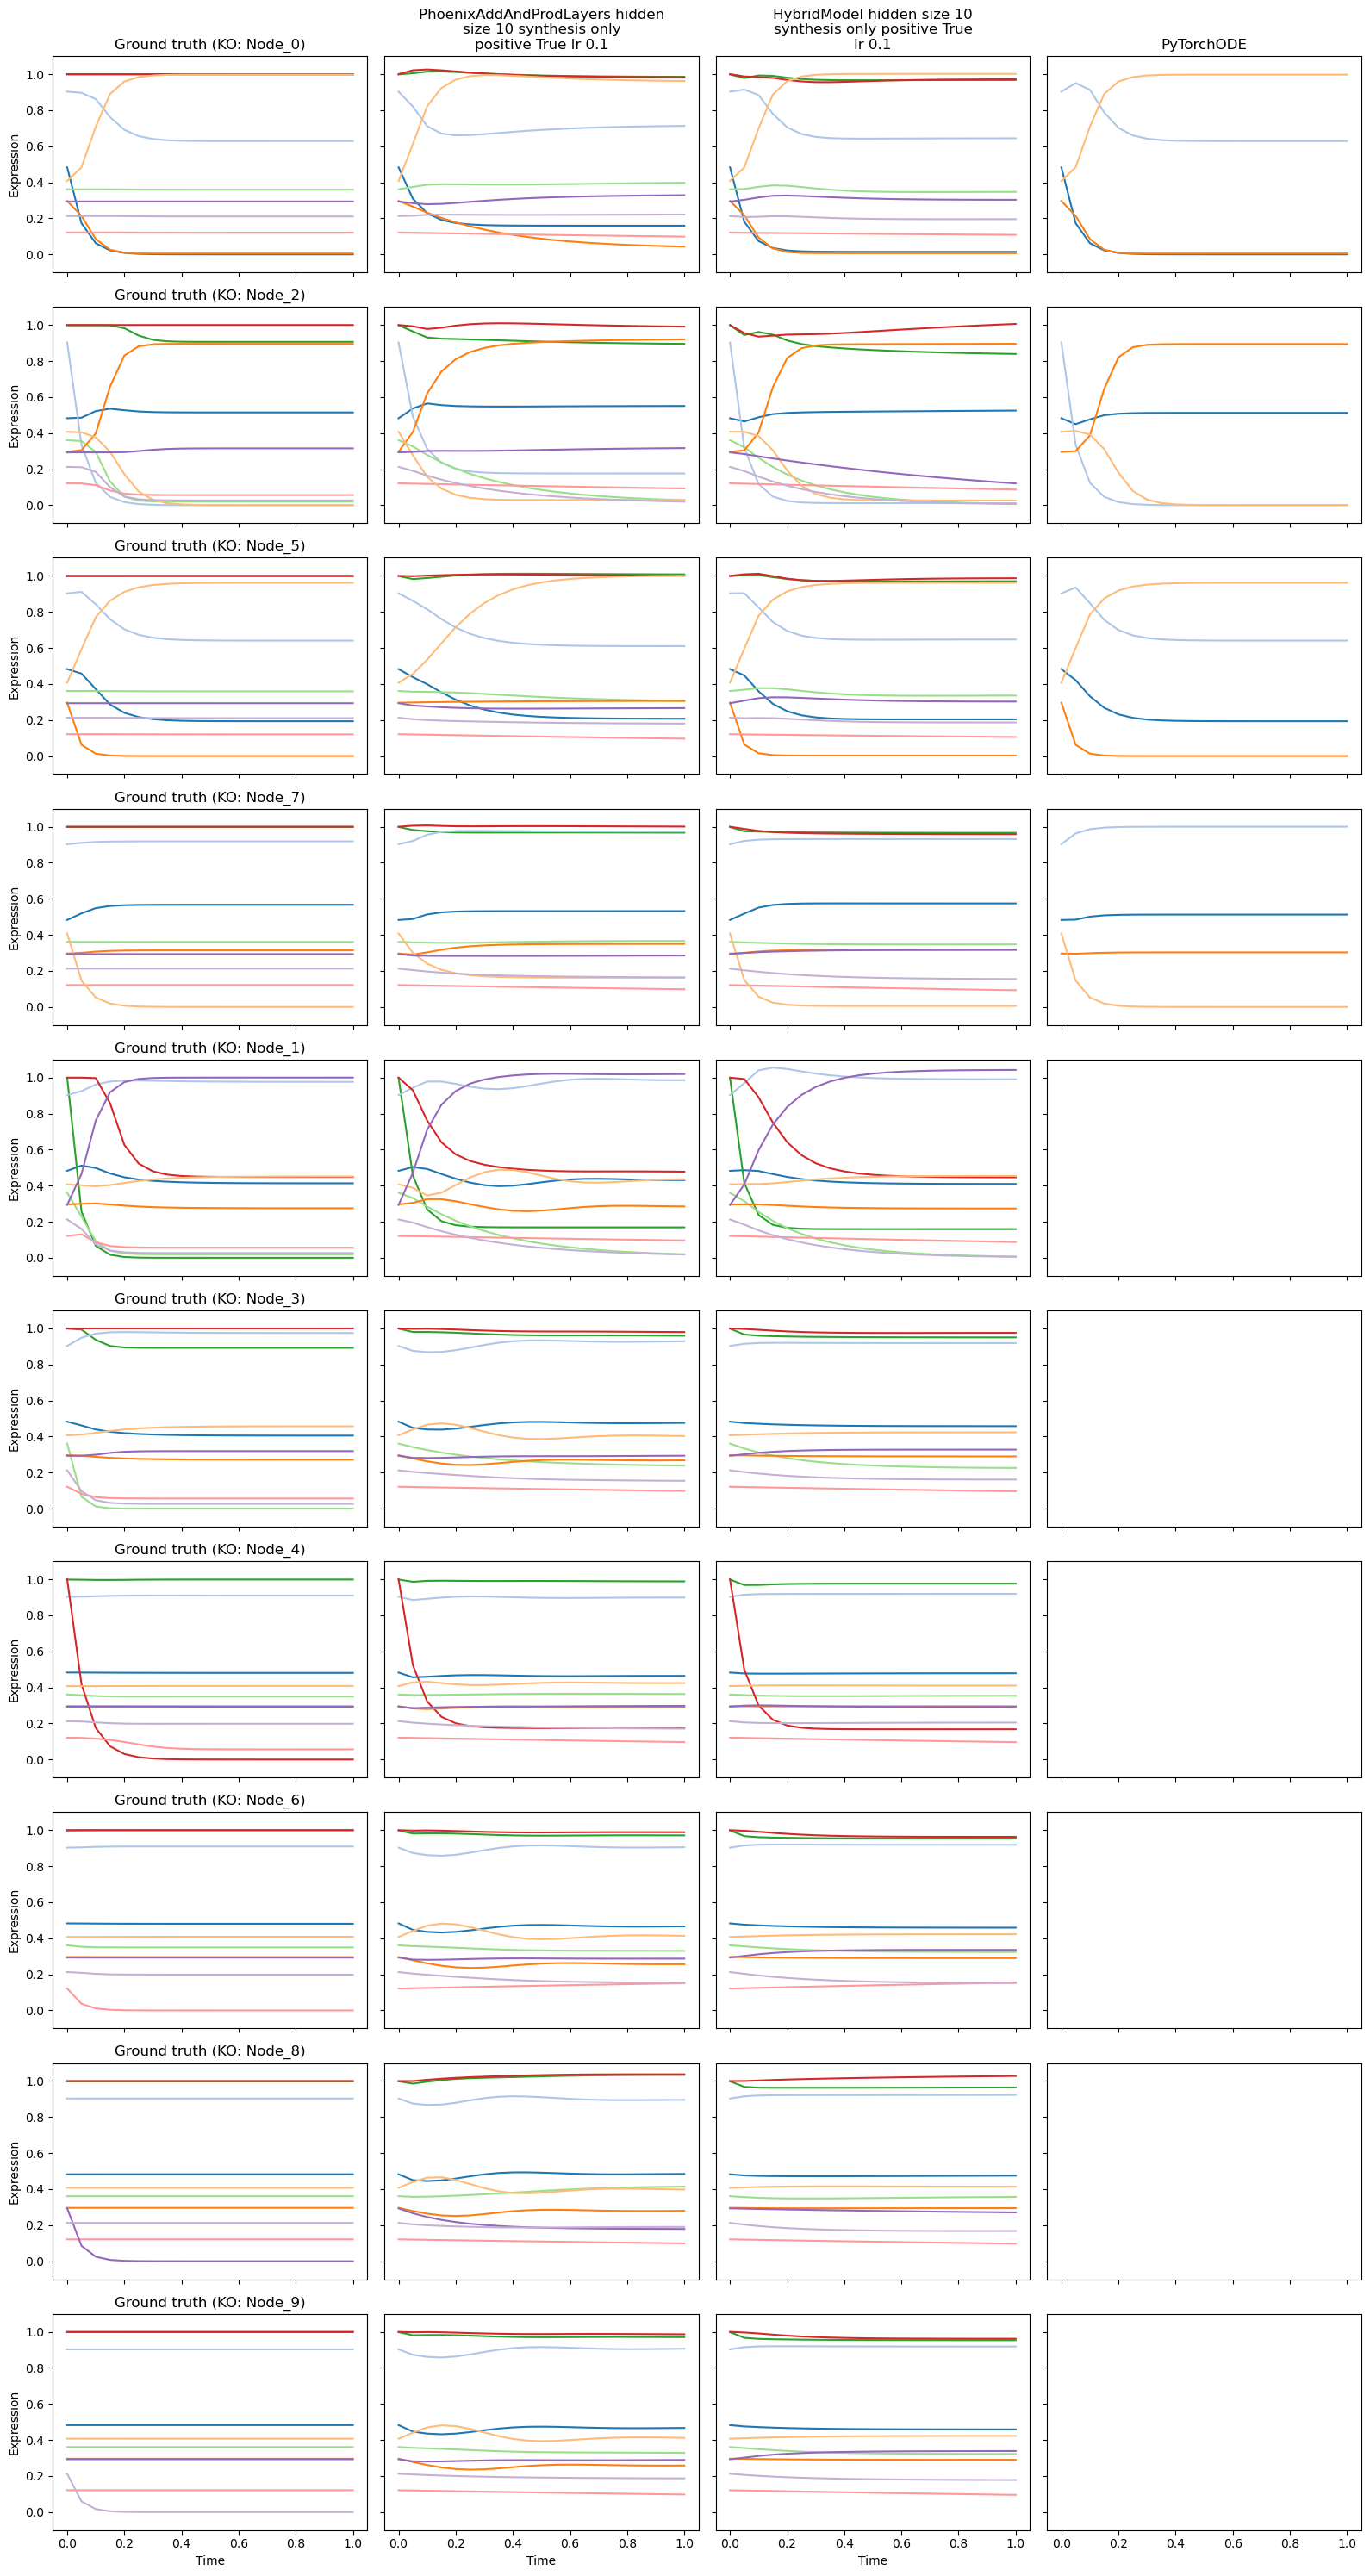

In [22]:
result_list.plot_all_model_fits_into_one_fig(ymin=-.1);plt.tight_layout();plt.show()

## Double KO (unseen)

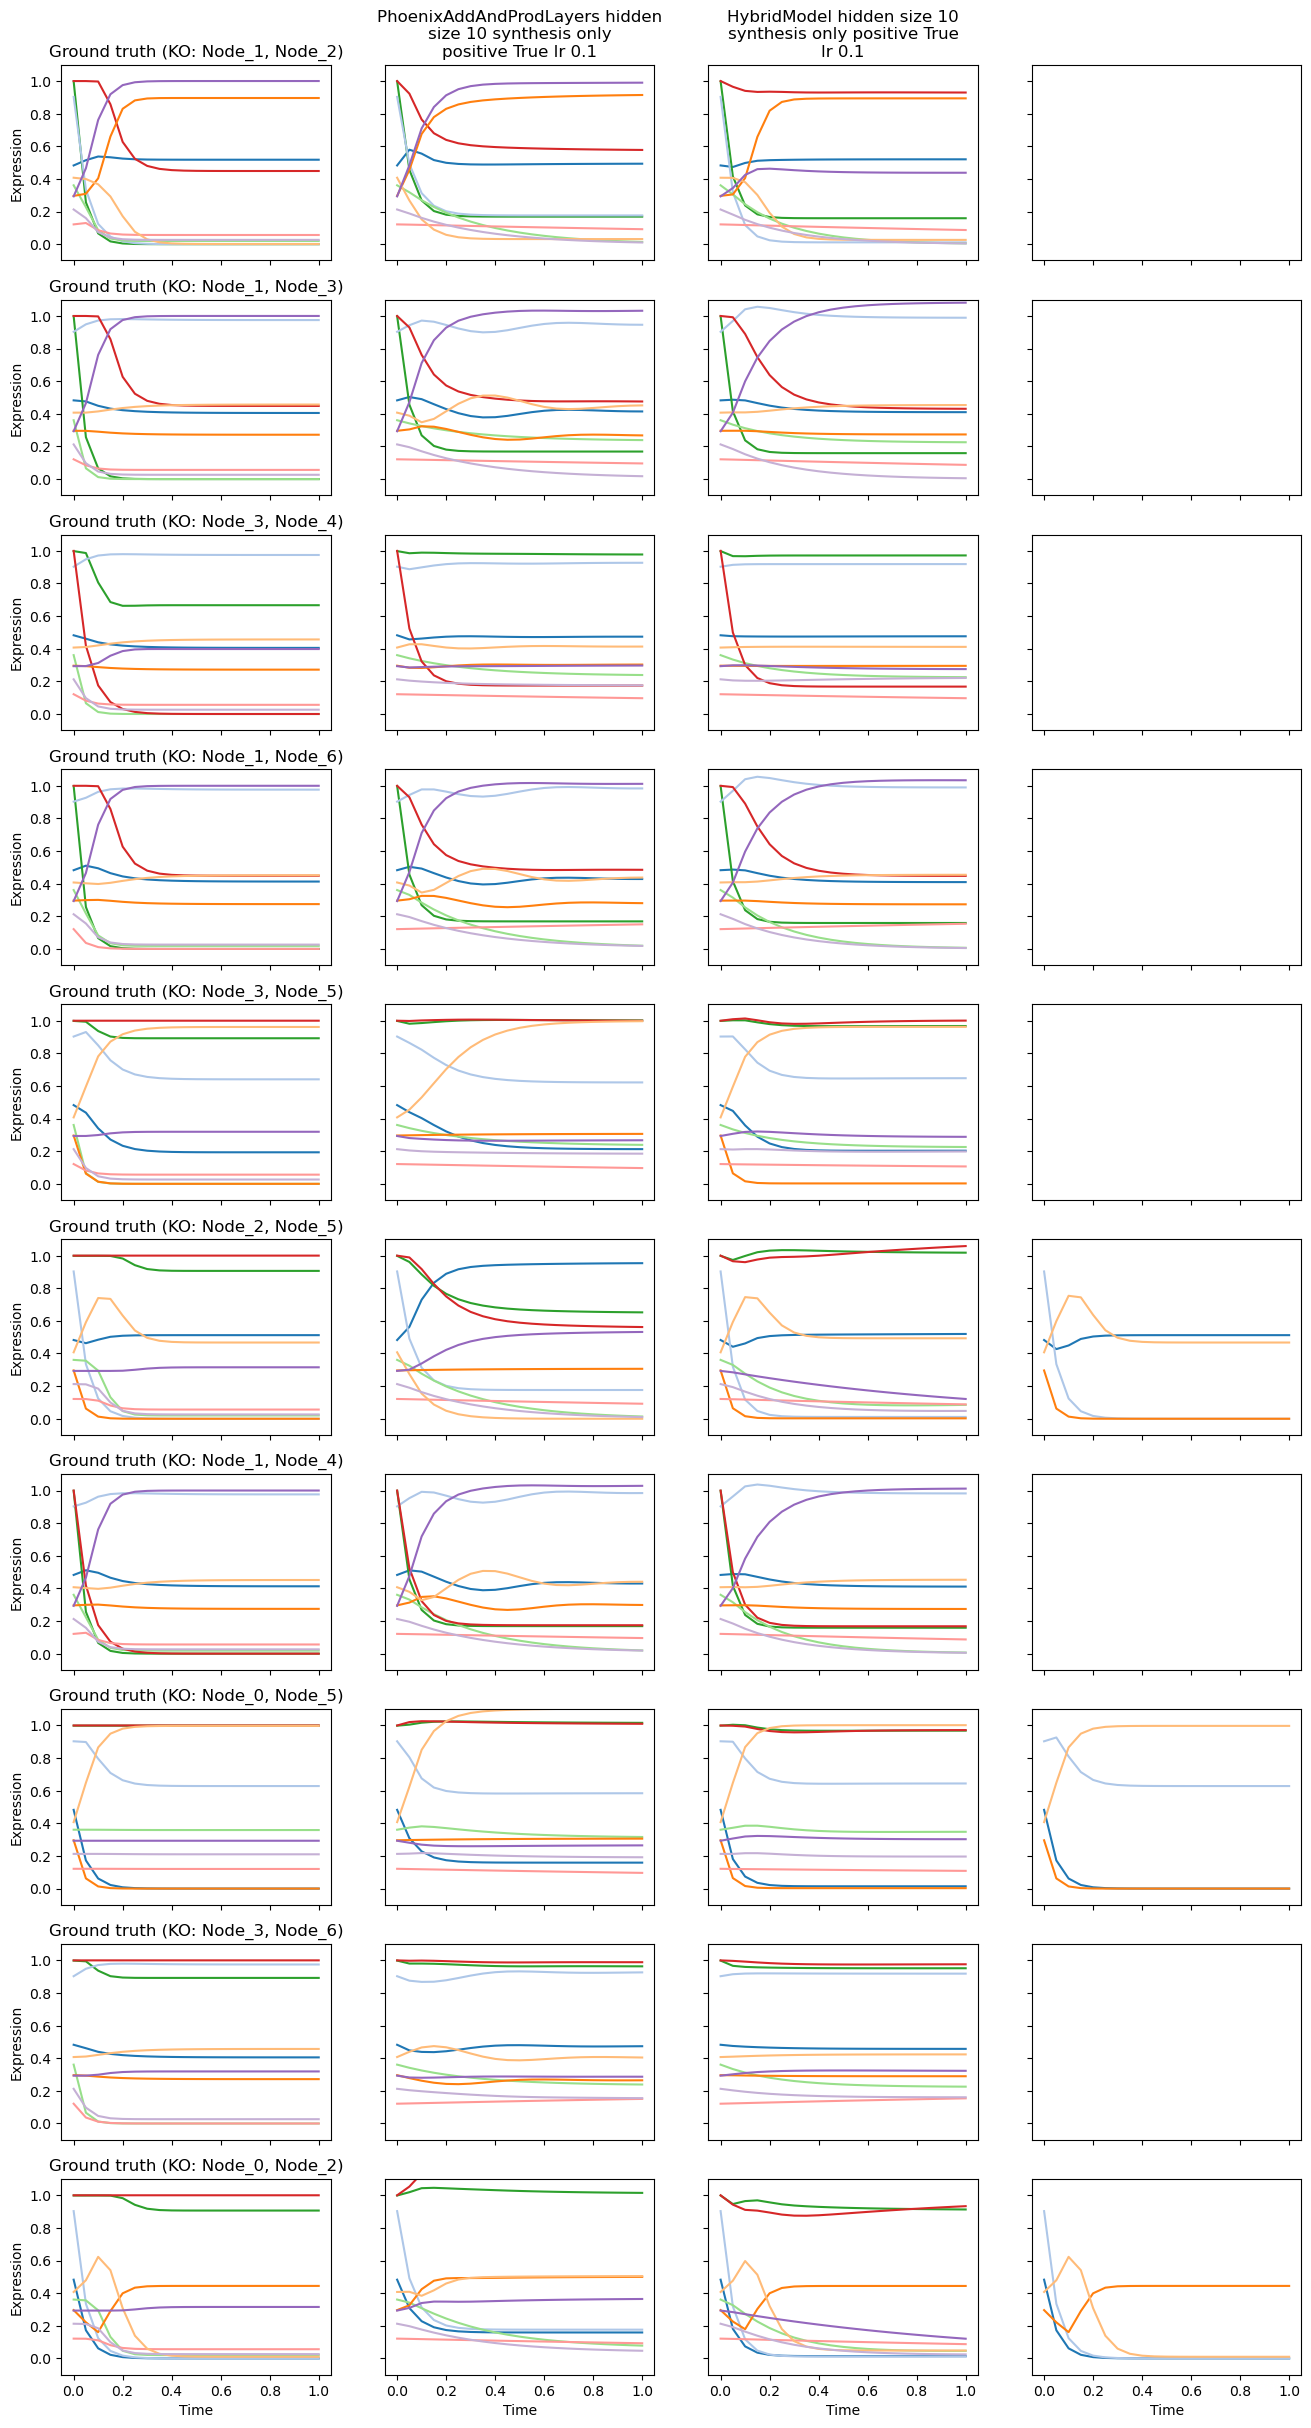

In [12]:
result_list.plot_all_model_fits_into_one_fig(only_double_ko=True, ymin=-.1);plt.show()

[]
[]
[]


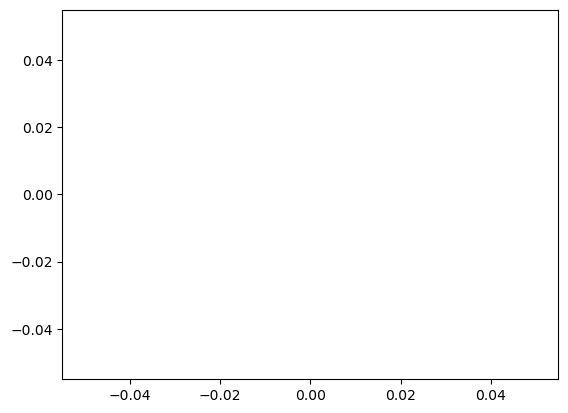

In [18]:
for result in result_list.trainer_list:
    print(result.loss_history)
    plt.plot(result.loss_history)
plt.show()

ValueError: zero-size array to reduction operation fmin which has no identity

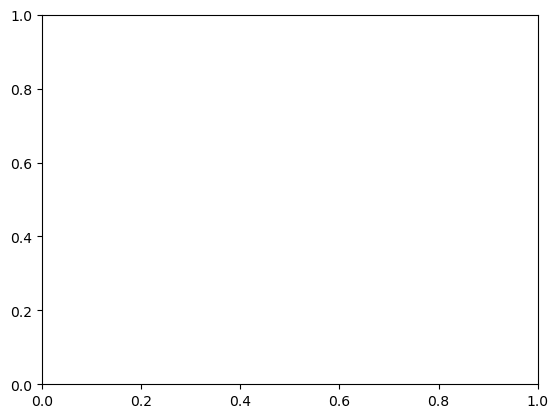

In [19]:
result_list.final_loss_heatmap()